extracting dataset using kaggle API

In [2]:
#installing the kaggle library
!pip install kaggle

In [3]:
#configureing the path of kaggle.json file
!mkdir -p ~/.kaggle
!cp /content/drive/MyDrive/AllDataset/kaggle.json ~/.kaggle/    #kaggle.json file every time uploaded karni padegi after a certain time it expire then you have to downoaded again and uploaded it
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle competitions download -c dogs-vs-cats


100% 812M/812M [00:09<00:00, 92.4MB/s]



In [5]:
!ls

 dogs-vs-cats.zip  'download cat.jpg'   drive  'images dog.jpg'   sample_data


In [6]:
#extracting the compressed dataset
from zipfile import ZipFile
dataset='/content/dogs-vs-cats.zip'
with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [7]:
#extracting the compressed dataset
from zipfile import ZipFile
dataset='/content/train.zip'
with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [8]:
import os
#counting the number of file in train folder
path,dirs,files=next(os.walk('/content/train'))
file_count=len(files)
print('number of imeges: ',file_count)

number of imeges:  25000


printing the names of images

In [9]:
file_names=os.listdir('/content/train')
print(file_names)

['dog.1853.jpg', 'dog.4223.jpg', 'cat.4930.jpg', 'dog.7832.jpg', 'cat.7546.jpg', 'dog.8907.jpg', 'cat.2341.jpg', 'cat.12022.jpg', 'dog.7278.jpg', 'cat.9179.jpg', 'dog.2715.jpg', 'dog.5361.jpg', 'cat.11715.jpg', 'cat.8556.jpg', 'dog.5930.jpg', 'cat.7893.jpg', 'cat.171.jpg', 'cat.6785.jpg', 'cat.7805.jpg', 'cat.106.jpg', 'cat.7171.jpg', 'dog.10034.jpg', 'dog.9623.jpg', 'dog.6248.jpg', 'cat.10656.jpg', 'dog.5804.jpg', 'cat.561.jpg', 'cat.12340.jpg', 'cat.8000.jpg', 'cat.8166.jpg', 'cat.11913.jpg', 'cat.3997.jpg', 'dog.4630.jpg', 'dog.4378.jpg', 'dog.850.jpg', 'dog.4070.jpg', 'cat.1306.jpg', 'cat.2991.jpg', 'cat.8355.jpg', 'dog.2370.jpg', 'dog.9261.jpg', 'dog.7411.jpg', 'cat.4997.jpg', 'dog.11898.jpg', 'dog.3843.jpg', 'cat.7280.jpg', 'cat.2937.jpg', 'dog.8886.jpg', 'dog.1243.jpg', 'cat.12055.jpg', 'cat.8955.jpg', 'dog.5229.jpg', 'dog.9689.jpg', 'dog.2691.jpg', 'dog.7677.jpg', 'dog.11680.jpg', 'dog.5244.jpg', 'cat.2684.jpg', 'cat.6331.jpg', 'dog.9960.jpg', 'cat.6115.jpg', 'dog.9782.jpg', 'd

importing the dependencies

In [10]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mping
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow

Displaying the image of dog and cats

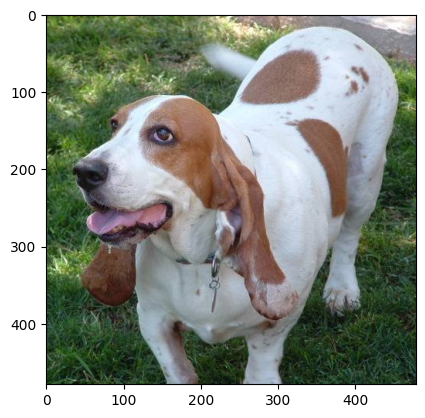

In [11]:
#displaying the dog
img=mping.imread('/content/train/dog.9541.jpg')
img_plot=plt.imshow(img)
plt.show()

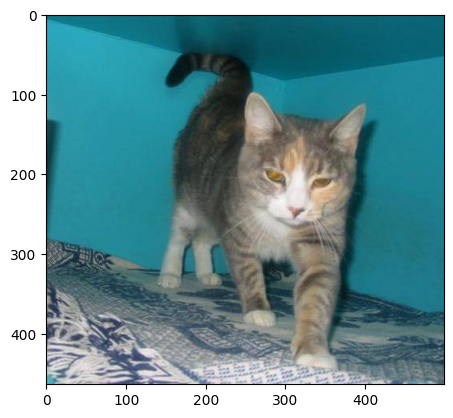

In [12]:
#displaying the cat
img=mping.imread('/content/train/cat.4757.jpg')
img_plot=plt.imshow(img)
plt.show()

In [13]:
file_names=os.listdir('/content/train')

for i in range(5):
  name=file_names[i]
  print(name)
  print(name[0:3])  # 0 to 2 index tak letter print kare

dog.1853.jpg
dog
dog.4223.jpg
dog
cat.4930.jpg
cat
dog.7832.jpg
dog
cat.7546.jpg
cat


In [14]:
file_names=os.listdir('/content/train')
dog_count=0
cat_count=0

for img_file in file_names:
  name=img_file[0:3]
  if name=='dog':
    dog_count+=1
  else:
    cat_count+=1

print('number of dog ',dog_count)
print('number of cat ',cat_count)

number of dog  12500
number of cat  12500


resizing all images

In [15]:
#creating a directory for resized image
os.mkdir('/content/image_resized')

In [16]:
original_folder='/content/train/'
resized_folder='/content/image_resized/'

for i in range(2000):   #taking 2000 image

  filename=os.listdir(original_folder)[i]
  img_path=original_folder+filename

  img=Image.open(img_path)
  img=img.resize((224,224))

  newimg_path=resized_folder+filename
  img.save(newimg_path)



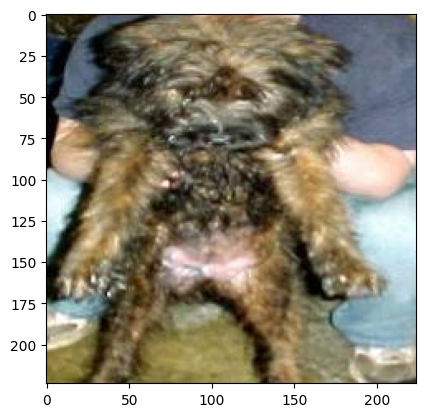

In [17]:
#displaying the resized image
img=mping.imread('/content/image_resized/dog.4223.jpg')
img_plot=plt.imshow(img)
plt.show()

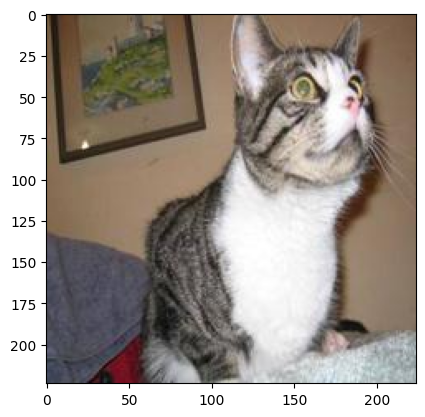

In [18]:
#displaying the cat resized
img=mping.imread('/content/image_resized/cat.4930.jpg')
img_plot=plt.imshow(img)
plt.show()

**creating label for resized images of dog and cat**

cat--->0

dog--->1

In [19]:
#creating for loop to assign label
filenames=os.listdir('/content/image_resized')
labels=[]

for i in range(2000):
  file_name=filenames[i]
  label=file_name[0:3]
  if label=='dog':
    labels.append(1)
  else:
    labels.append(0)


In [20]:
print(filenames[0:5])
print(len(filenames))

['dog.1853.jpg', 'dog.4223.jpg', 'cat.4930.jpg', 'dog.7832.jpg', 'cat.7546.jpg']
2000


In [21]:
print(labels[0:5])
print(len(labels))

[1, 1, 0, 1, 0]
2000


In [22]:
#counting image of cats and dogs out of 2000 image
values,counts=np.unique(labels,return_counts=True)
print(values)
print(counts)

[0 1]
[1010  990]


converting all resized image to numpy array


In [23]:
import cv2
import glob

In [24]:
image_directory='/content/image_resized/'
image_extension=['png','jpg']

files=[]

[files.extend(glob.glob(image_directory + '*' + e)) for e in image_extension]

dog_cat_images=np.asarray([cv2.imread(file) for file in files])



In [25]:
print(dog_cat_images.shape)

(2000, 224, 224, 3)


In [26]:
print(dog_cat_images)

[[[[143 159 172]
   [143 159 172]
   [144 160 173]
   ...
   [124 153 168]
   [122 148 164]
   [120 146 162]]

  [[144 160 173]
   [140 156 169]
   [135 151 164]
   ...
   [132 161 176]
   [132 158 175]
   [131 157 173]]

  [[141 157 170]
   [133 149 162]
   [125 141 154]
   ...
   [136 164 181]
   [138 163 183]
   [137 163 180]]

  ...

  [[ 86  90 108]
   [ 76  80  98]
   [ 76  80  98]
   ...
   [ 76  81  96]
   [ 75  80  95]
   [ 78  83  98]]

  [[100 104 122]
   [ 88  92 110]
   [ 78  82 100]
   ...
   [ 72  77  92]
   [ 77  82  97]
   [ 87  92 107]]

  [[114 118 136]
   [109 113 131]
   [ 98 102 120]
   ...
   [ 55  60  75]
   [ 64  69  84]
   [ 81  86 101]]]


 [[[ 28  43  45]
   [ 24  39  41]
   [ 21  39  40]
   ...
   [ 97 150 163]
   [101 161 177]
   [ 99 164 179]]

  [[ 43  58  60]
   [ 29  47  48]
   [ 18  36  37]
   ...
   [ 94 141 155]
   [ 99 154 169]
   [ 99 158 173]]

  [[ 58  75  78]
   [ 38  57  60]
   [ 16  35  38]
   ...
   [ 87 125 137]
   [ 92 137 150]
   [ 93 143

In [28]:
type(dog_cat_images)

numpy.ndarray

In [29]:
x=dog_cat_images
y=np.asarray(labels)

**train test split**

In [30]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [ ]:
print(x.shape,x_train.shape,x_test.shape)

(2000, 224, 224, 3) (1600, 224, 224, 3) (400, 224, 224, 3)


1600--->training images

400--->test images

In [31]:
#scaling the data
x_train_scaled=x_train/255
x_test_scaled=x_test/255

In [32]:
print(x_train_scaled)

[[[[0.27058824 0.4627451  0.63529412]
   [0.28235294 0.4745098  0.64705882]
   [0.28627451 0.4627451  0.63529412]
   ...
   [0.34509804 0.41960784 0.56862745]
   [0.35686275 0.43137255 0.58039216]
   [0.37254902 0.44705882 0.59607843]]

  [[0.2627451  0.45098039 0.61568627]
   [0.2745098  0.45098039 0.61960784]
   [0.2627451  0.43921569 0.60784314]
   ...
   [0.34117647 0.41568627 0.56470588]
   [0.35294118 0.42745098 0.57647059]
   [0.36078431 0.43529412 0.58431373]]

  [[0.26666667 0.43137255 0.59607843]
   [0.25882353 0.42352941 0.58823529]
   [0.23921569 0.40392157 0.56862745]
   ...
   [0.35294118 0.42745098 0.57254902]
   [0.36078431 0.43529412 0.58039216]
   [0.36470588 0.43921569 0.58431373]]

  ...

  [[0.68627451 0.6745098  0.70980392]
   [0.70588235 0.69411765 0.72941176]
   [0.7254902  0.71372549 0.74901961]
   ...
   [0.3372549  0.32156863 0.36862745]
   [0.37647059 0.36078431 0.40784314]
   [0.41176471 0.39607843 0.44313725]]

  [[0.61960784 0.60784314 0.64313725]
   [0.6

building the Neural Network

In [33]:
!pip uninstall tensorflow
%pip install tensorflow==2.21.0 tensorflow-hub
# !pip install tensorflow==2.15.0 tensorflow-hub keras      #keras ko separately install mat karo, kyunki TensorFlow apni compatible Keras dependency install karega.

Found existing installation: tensorflow 2.21.0
Uninstalling tensorflow-2.21.0:
  Would remove:
    /usr/local/bin/saved_model_cli
    /usr/local/bin/tf_upgrade_v2
    /usr/local/bin/tflite_convert
    /usr/local/bin/toco
    /usr/local/lib/python3.13/dist-packages/tensorflow-2.21.0.dist-info/*
    /usr/local/lib/python3.13/dist-packages/tensorflow/*
Proceed (Y/n)? y
  Successfully uninstalled tensorflow-2.21.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 45.5 MB/s  0:00:09


In [35]:
import tensorflow as tf
import tensorflow_hub as hub

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [36]:
mobilenet_model='https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4'
pretrained_model=hub.KerasLayer(mobilenet_model,input_shape=(224,224,3),trainable=False)

In [37]:
import tf_keras as keras

num_of_class = 2
model = keras.Sequential([
    pretrained_model,
    keras.layers.Dense(num_of_class)
])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 2260546 (8.62 MB)
Trainable params: 2562 (10.01 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


In [38]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['acc']
)

In [39]:
model.fit(x_train_scaled,y_train,epochs=5)

Epoch 1/5
50/50 [==============================] - 52s 963ms/step - loss: 0.1864 - acc: 0.9225
Epoch 2/5
50/50 [==============================] - 48s 969ms/step - loss: 0.0549 - acc: 0.9831
Epoch 3/5
50/50 [==============================] - 48s 965ms/step - loss: 0.0395 - acc: 0.9875
Epoch 4/5
50/50 [==============================] - 49s 976ms/step - loss: 0.0313 - acc: 0.9925
Epoch 5/5
50/50 [==============================] - 50s 989ms/step - loss: 0.0247 - acc: 0.9956


In [40]:
score,acc=model.evaluate(x_test_scaled,y_test)
print('test loss',score)
print('test accuracy',acc)

13/13 [==============================] - 12s 895ms/step - loss: 0.0760 - acc: 0.9775
test loss 0.07595907151699066
test accuracy 0.9775000214576721


**Predictive system**


path of the image to be predicted:/content/images dog.jpg


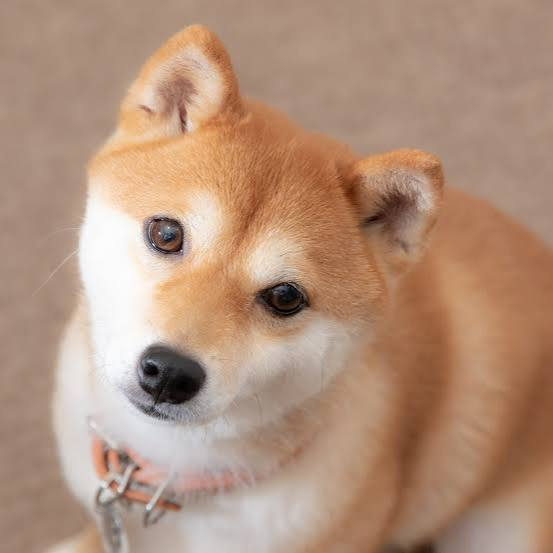

1/1 [==============================] - 0s 45ms/step
[[-1.0788255  -0.08653405]]
1
the image is dog


In [42]:
input_image_path=input('path of the image to be predicted:')

input_image=cv2.imread(input_image_path)

cv2_imshow(input_image)

input_image_resize=cv2.resize(input_image,(224,224))

input_image_scaled=input_image_resize/255

image_reshaped=np.reshape(input_image_scaled,[1,224,224,3])

input_prediction=model.predict(image_reshaped)

print(input_prediction)

input_prediction_label=np.argmax(input_prediction)

print(input_prediction_label)

if input_prediction_label==0:
  print('the image is cat')
else:
  print('the image is dog')


In [43]:
model.save('/content/dog_cat_model.keras')